## **Data Ingestion**

In [0]:
import pandas as pd
import numpy as np

In [0]:
encounters = spark.table("analystlab.default.encounters").toPandas()

encounters.head()

,Id,START,STOP,PATIENT,ORGANIZATION,PAYER,ENCOUNTERCLASS,CODE,DESCRIPTION,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE,REASONCODE,REASONDESCRIPTION
0,32c84703-2481-49cd-d571-3899d5820253,2011-01-02 09:26:36,2011-01-02 12:58:36,3de74169-7f67-9304-91d4-757e0f3a14d2,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,ambulatory,185347001,Encounter for problem (procedure),85.55,1018.02,0.00,NaN,None
1,c98059da-320a-c0a6-fced-c8815f3e3f39,2011-01-03 05:44:39,2011-01-03 06:01:42,d9ec2e44-32e9-9148-179a-1653348cc4e2,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,outpatient,308335008,Patient encounter procedure,142.58,2619.36,0.00,NaN,None
2,4ad28a3a-2479-782b-f29c-d5b3f41a001e,2011-01-03 14:32:11,2011-01-03 14:47:11,73babadf-5b2b-fee7-189e-6f41ff213e01,d78e84ec-30aa-3bba-a33a-f29a3a454662,7caa7254-5050-3b5e-9eae-bd5ea30e809c,outpatient,185349003,Encounter for check up (procedure),85.55,461.59,305.27,NaN,None
3,c3f4da61-e4b4-21d5-587a-fbc89943bc19,2011-01-03 16:24:45,2011-01-03 16:39:45,3b46a0b7-0f34-9b9a-c319-ace4a1f58c0b,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,wellness,162673000,General examination of patient (procedure),136.80,1784.24,0.00,NaN,None
4,a9183b4f-2572-72ea-54c2-b3cd038b4be7,2011-01-03 17:36:53,2011-01-03 17:51:53,fa006887-d93c-d302-8b89-f3c25f88c0e1,d78e84ec-30aa-3bba-a33a-f29a3a454662,42c4fca7-f8a9-3cd1-982a-dd9751bf3e2a,ambulatory,390906007,Follow-up encounter,85.55,234.72,0.00,55822004.0,Hyperlipidemia


Exploritary Data (EDA)

In [0]:
# Display all column names
print(encounters.columns.tolist())

['Id', 'START', 'STOP', 'PATIENT', 'ORGANIZATION', 'PAYER', 'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST', 'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE', 'REASONDESCRIPTION']


In [0]:
 # Check the data types
print(encounters.dtypes)

Id                             object
START                  datetime64[ns]
STOP                   datetime64[ns]
PATIENT                        object
ORGANIZATION                   object
PAYER                          object
ENCOUNTERCLASS                 object
CODE                            int64
DESCRIPTION                    object
BASE_ENCOUNTER_COST           float64
TOTAL_CLAIM_COST              float64
PAYER_COVERAGE                float64
REASONCODE                    float64
REASONDESCRIPTION              object
dtype: object


In [0]:
# Check the number of encounter records
print("Dataset shape:", encounters.shape)

Dataset shape: (27891, 14)


In [0]:
# Count records in each encounter class
print("\nEncounter class counts:")
print(encounters["ENCOUNTERCLASS"].value_counts()) 


Encounter class counts:
ENCOUNTERCLASS
ambulatory    12537
outpatient     6300
urgentcare     3666
emergency      2322
wellness       1931
inpatient      1135
Name: count, dtype: int64


In [0]:
# Check missing values in the relevant columns
print("\nMissing values:")
print(
    encounters[
        ["ENCOUNTERCLASS", "BASE_ENCOUNTER_COST", "TOTAL_CLAIM_COST"]
    ].isnull().sum()
)



Missing values:
ENCOUNTERCLASS         0
BASE_ENCOUNTER_COST    0
TOTAL_CLAIM_COST       0
dtype: int64


In [0]:
# Summary statistics for both cost measures
print("\nCost summary:")
print(
    encounters[
        ["BASE_ENCOUNTER_COST", "TOTAL_CLAIM_COST"]
    ].describe()
)


Cost summary:
       BASE_ENCOUNTER_COST  TOTAL_CLAIM_COST
count         27891.000000      27891.000000
mean            116.181614       3639.682174
std              28.410082       9205.595748
min              85.550000          0.000000
25%              85.550000        142.580000
50%             136.800000        278.580000
75%             142.580000       1412.530000
max             146.180000     641882.700000


In [0]:
 # Calculate cost statistics for each encounter class
class_cost_summary = encounters.groupby("ENCOUNTERCLASS").agg(
    Encounter_Count=("Id", "count"),

    Mean_Base_Cost=("BASE_ENCOUNTER_COST", "mean"),
    Median_Base_Cost=("BASE_ENCOUNTER_COST", "median"),

    Mean_Total_Claim=("TOTAL_CLAIM_COST", "mean"),
    Median_Total_Claim=("TOTAL_CLAIM_COST", "median"),

    Std_Total_Claim=("TOTAL_CLAIM_COST", "std")
).round(2)

# Display the results
display(class_cost_summary)

Encounter_Count,Mean_Base_Cost,Median_Base_Cost,Mean_Total_Claim,Median_Total_Claim,Std_Total_Claim
12537,105.73,85.55,2894.11,573.98,7124.38
2322,145.25,146.18,4629.65,146.18,16049.34
1135,113.67,87.71,7761.35,2355.59,15017.44
6300,105.04,85.55,2237.3,278.58,5717.27
3666,142.58,142.58,6369.16,142.58,11232.81
1931,136.8,136.8,4260.71,1231.44,8403.69


<Figure size 1200x600 with 0 Axes>

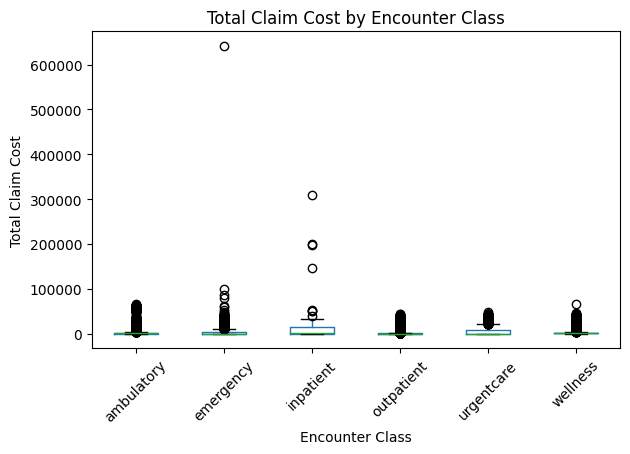

In [0]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

encounters.boxplot(
    column="TOTAL_CLAIM_COST",
    by="ENCOUNTERCLASS",
    grid=False
)

plt.title("Total Claim Cost by Encounter Class")
plt.suptitle("")
plt.xlabel("Encounter Class")
plt.ylabel("Total Claim Cost")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Levene's Test for Equality of Variances**

Levene's test was conducted to assess whether total claim cost variances were equal across the six encounter classes. The test produced a statistic of 159.17 and a p-value of approximately 2.33 × 10⁻¹⁶⁷. Since the p-value was below the 0.05 significance level, the null hypothesis of equal variances was rejected. This indicates that encounter cost variability differs significantly across encounter classes. Consequently, Welch's ANOVA was selected as a more appropriate method for comparing mean costs because it accommodates unequal group variances.

In [0]:
from scipy.stats import levene

# Separate total claim costs for each encounter class
cost_groups = [
    group["TOTAL_CLAIM_COST"].values
    for name, group in encounters.groupby("ENCOUNTERCLASS")
]

# Perform Levene's test
levene_stat, levene_p = levene(*cost_groups, center="median")

# Display results
print("Levene Test Statistic:", levene_stat)
print("P-value:", levene_p)

Levene Test Statistic: 159.166696790111
P-value: 2.3251976605848253e-167


In [0]:
%pip install pingouin

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
 # Import Welch's ANOVA
from scipy.stats import f_oneway

# Collect total claim costs for each encounter class
cost_groups = [
    group["TOTAL_CLAIM_COST"].values
    for name, group in encounters.groupby("ENCOUNTERCLASS")
]

# Perform Welch's ANOVA
from scipy.stats import f_oneway
import pingouin as pg

welch_result = pg.welch_anova(
    data=encounters,
    dv="TOTAL_CLAIM_COST",
    between="ENCOUNTERCLASS"
)

# Display the results
display(welch_result)

Source,ddof1,ddof2,F,p_unc,np2
ENCOUNTERCLASS,5,5636.848025120847,125.17655386141202,4.7215310014601096E-126,0.029182820753437335


In [0]:
from scipy.stats import levene

# Separate base encounter costs by encounter class
base_cost_groups = [
    group["BASE_ENCOUNTER_COST"].values
    for name, group in encounters.groupby("ENCOUNTERCLASS")
]

# Perform Levene's test
base_stat, base_p = levene(
    *base_cost_groups,
    center="median"
)

print("Levene Test Statistic:", base_stat)
print("P-value:", base_p) 

Levene Test Statistic: 859.6187640258465
P-value: 0.0


In [0]:
import pingouin as pg

# Exclude classes with a constant base cost (zero variance),
# where Welch's ANOVA weights are undefined
base_cost_var = encounters.groupby("ENCOUNTERCLASS")["BASE_ENCOUNTER_COST"].var()
test_data = encounters[
    encounters["ENCOUNTERCLASS"].isin(base_cost_var[base_cost_var > 0].index)
]

# Perform Welch's ANOVA on base encounter costs
welch_base_result = pg.welch_anova(
    data=test_data,
    dv="BASE_ENCOUNTER_COST",
    between="ENCOUNTERCLASS"
)

# Display the results
display(welch_base_result)

Source,ddof1,ddof2,F,p_unc,np2
ENCOUNTERCLASS,3,4631.570588280043,8569.683541808286,0.0,0.17946317034257867


In [0]:
 # Check the number of encounter classes
print("Number of encounter classes:",
      encounters["ENCOUNTERCLASS"].nunique())

# Display the encounter class names
print(encounters["ENCOUNTERCLASS"].value_counts())

# Check for missing values
print("Missing encounter classes:",
      encounters["ENCOUNTERCLASS"].isna().sum())

# Check the number of groups used for base cost
print("Base cost groups:",
      len(base_cost_groups))

Number of encounter classes: 6
ENCOUNTERCLASS
ambulatory    12537
outpatient     6300
urgentcare     3666
emergency      2322
wellness       1931
inpatient      1135
Name: count, dtype: int64
Missing encounter classes: 0
Base cost groups: 6


In [0]:
 # Examine base encounter costs within each class
base_cost_check = encounters.groupby("ENCOUNTERCLASS")[
    "BASE_ENCOUNTER_COST"
].agg(
    Count="count",
    Unique_Values="nunique",
    Mean="mean",
    Standard_Deviation="std",
    Minimum="min",
    Maximum="max"
)

display(base_cost_check)

# Run Welch's ANOVA again
welch_base_result = pg.welch_anova(
    data=encounters,
    dv="BASE_ENCOUNTER_COST",
    between="ENCOUNTERCLASS"
)

display(welch_base_result)

Count,Unique_Values,Mean,Standard_Deviation,Minimum,Maximum
12537,2,105.7290763340512,27.270440410930764,85.55,142.58
2322,2,145.24830749354007,7.323326216369854,87.71,146.18
1135,2,113.67377092511013,29.064214070906377,87.71,146.18
6300,2,105.03977619047619,27.05118691729836,85.55,142.58
3666,1,142.58,0.0,142.58,142.58
1931,1,136.8,0.0,136.8,136.8


---------------------------------------------------------------------------
ValueError                                Traceback (most recent call last)
File <command-7133451555539310>, line 16
     13 display(base_cost_check)
     15 # Run Welch's ANOVA again
---> 16 welch_base_result = pg.welch_anova(
     17     data=encounters,
     18     dv="BASE_ENCOUNTER_COST",
     19     between="ENCOUNTERCLASS"
     20 )
     22 display(welch_base_result)

File /local_disk0/.ephemeral_nfs/envs/pythonEnv-827c8242-ca72-434c-8580-1a44bf8798e7/lib/python3.12/site-packages/pingouin/parametric.py:1335, in welch_anova(data, dv, between)
   1333 grp = data.groupby(between, observed=True, group_keys=False)[dv]
   1334 if (grp.count() < 2).any() or (grp.var() == 0).any():
-> 1335     raise ValueError(
   1336         "Each group must have at least two observations and a non-zero variance. "
   1337         "The Welch ANOVA weights are undefined otherwise."
   1338     )
   1339 weights = grp.count() / 

In [0]:
 # Display the distinct base costs in each encounter class
for class_name, group in encounters.groupby("ENCOUNTERCLASS"):

    print("\nEncounter Class:", class_name)

    print(
        group["BASE_ENCOUNTER_COST"]
        .value_counts()
        .sort_index()
    )


Encounter Class: ambulatory
BASE_ENCOUNTER_COST
85.55     8101
142.58    4436
Name: count, dtype: int64

Encounter Class: emergency
BASE_ENCOUNTER_COST
87.71       37
146.18    2285
Name: count, dtype: int64

Encounter Class: inpatient
BASE_ENCOUNTER_COST
87.71     631
146.18    504
Name: count, dtype: int64

Encounter Class: outpatient
BASE_ENCOUNTER_COST
85.55     4147
142.58    2153
Name: count, dtype: int64

Encounter Class: urgentcare
BASE_ENCOUNTER_COST
142.58    3666
Name: count, dtype: int64

Encounter Class: wellness
BASE_ENCOUNTER_COST
136.8    1931
Name: count, dtype: int64


In [0]:
from scipy.stats import chi2_contingency

# Create a frequency table
base_cost_table = pd.crosstab(
    encounters["ENCOUNTERCLASS"],
    encounters["BASE_ENCOUNTER_COST"]
)

# Display the frequency table
display(base_cost_table)

# Perform the Chi-square test
chi2_stat, p_value, degrees_freedom, expected = (
    chi2_contingency(base_cost_table)
)

# Display the results
print("Chi-square statistic:", chi2_stat)
print("P-value:", p_value)
print("Degrees of freedom:", degrees_freedom)

# Check expected frequencies
print("\nExpected frequencies:")
display(pd.DataFrame(
    expected,
    index=base_cost_table.index,
    columns=base_cost_table.columns
))

85.55,87.71,136.8,142.58,146.18
8101,0,0,4436,0
0,37,0,0,2285
0,631,0,0,504
4147,0,0,2153,0
0,0,0,3666,0
0,0,1931,0,0


Chi-square statistic: 73773.52142513248
P-value: 0.0
Degrees of freedom: 20

Expected frequencies:


85.55,87.71,136.8,142.58,146.18
5505.474023878671,300.26589222329784,867.9841884478864,4609.620845434011,1253.6550500161343
1019.6786060019361,55.61277831558567,160.76089060987417,853.756050338819,232.19167473378508
498.4217130974149,27.18367932307913,78.5803664264458,417.3183105661324,113.49593058692768
2766.569861245563,150.88738302678283,436.1729590190384,2316.3923846402067,629.9774120684092
1609.8801764009895,87.80208669463268,253.811121867269,1347.9197590620631,366.5868559750457
847.9756193754257,46.24818041662185,133.6904736294862,709.9926499587681,193.0930766196981


**Chi-square Test of Independence – Base Encounter Cost**

A Chi-square test of independence was conducted to investigate the relationship between encounter class and base encounter cost category. The test produced a Chi-square statistic of 73,773.52 with 20 degrees of freedom and a p-value below 0.05 (reported as 0.0 due to numerical rounding). Therefore, the null hypothesis of independence was rejected. The results provide strong evidence of an association between encounter class and base encounter cost category.

Cramér's V was approximately 0.813, indicating a strong association. The analysis showed that certain encounter classes were consistently linked to particular base cost values. For example, all urgent care encounters had a base cost of 142.58, while all wellness encounters had a base cost of 136.80.

Although the expected-frequency guideline was satisfied, the dataset contains structural zero cells because certain cost values do not occur in particular encounter classes. This suggests that predefined pricing arrangements may explain much of the observed association. Additionally, repeated encounters from individual patients may affect the independence assumption. Consequently, the findings demonstrate an association in the dataset but do not establish a causal relationship or explain differences in total healthcare expenditure.

In [0]:
import numpy as np

# Calculate Cramér's V
n = base_cost_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2_stat / (n * min(
        base_cost_table.shape[0] - 1,
        base_cost_table.shape[1] - 1
    ))
)

print("Cramér's V:", cramers_v)

Cramér's V: 0.813182864488424


In [0]:
 # Games-Howell post-hoc pairwise comparisons
games_howell_results = pg.pairwise_gameshowell(
    data=encounters,
    dv="TOTAL_CLAIM_COST",
    between="ENCOUNTERCLASS"
)

# Display the results
display(games_howell_results.round(4))

A,B,mean_A,mean_B,diff,se,T,df,pval,hedges
ambulatory,emergency,2894.1087,4629.6518,-1735.5431,339.0861,-5.1183,2492.8923,0.0,-0.1904
ambulatory,inpatient,2894.1087,7761.3518,-4867.2431,450.2751,-10.8095,1180.6377,0.0,-0.6025
ambulatory,outpatient,2894.1087,2237.2964,656.8123,96.1093,6.834,15287.4809,0.0,0.0982
ambulatory,urgentcare,2894.1087,6369.1626,-3475.0539,196.1287,-17.7182,4559.4907,0.0,-0.422
ambulatory,wellness,2894.1087,4260.7104,-1366.6017,201.5472,-6.7806,2376.4648,0.0,-0.187
emergency,inpatient,4629.6518,7761.3518,-3131.7,556.444,-5.6281,2389.7259,0.0,-0.1992
emergency,outpatient,4629.6518,2237.2964,2392.3555,340.7628,7.0206,2541.1437,0.0,0.2477
emergency,urgentcare,4629.6518,6369.1626,-1739.5107,381.2463,-4.5627,3755.7177,1.0E-4,-0.1307
emergency,wellness,4629.6518,4260.7104,368.9414,384.0619,0.9606,3629.2938,0.9302,0.0281
inpatient,outpatient,7761.3518,2237.2964,5524.0555,451.5391,12.2338,1193.8487,0.0,0.7009


In [0]:
from scipy.stats import kruskal

# Separate total claim costs by encounter class
groups = [
    group["TOTAL_CLAIM_COST"].values
    for name, group in encounters.groupby("ENCOUNTERCLASS")
]

# Perform the Kruskal-Wallis test
kruskal_stat, kruskal_p = kruskal(*groups)

# Display results
print("Kruskal-Wallis Statistic:", kruskal_stat)
print("P-value:", kruskal_p)

Kruskal-Wallis Statistic: 2025.1937917704458
P-value: 0.0


Task 3 – Practical significance and limitations

The statistical investigation found that encounter class is associated with differences in healthcare encounter costs. Welch's ANOVA and the Kruskal–Wallis test both identified statistically significant differences in total claim costs across encounter classes. The Games–Howell post-hoc analysis showed that inpatient encounters had the highest average total claim cost, while outpatient encounters had the lowest. Furthermore, the Chi-square test and Cramér's V indicated a strong association between encounter class and base encounter cost category. These findings suggest that encounter class is an important factor to consider when investigating hospital cost patterns. However, the results should be interpreted with caution because of skewed cost distributions, repeated patient encounters and possible predefined pricing arrangements.

In [0]:
 # Count the total number of encounter records
total_encounters = len(encounters)

In [0]:
 # Count the number of unique patients
unique_patients = encounters["PATIENT"].nunique()

In [0]:
 # Count how many encounters each patient has
patient_encounter_counts = encounters["PATIENT"].value_counts()

In [0]:
 # Identify patients with more than one encounter
repeated_patients = patient_encounter_counts[
    patient_encounter_counts > 1
]

In [0]:
# Calculate the number of patients with multiple encounters
number_repeated_patients = len(repeated_patients) 

In [0]:
# Display the results
print("Total encounter records:", total_encounters)
print("Unique patients:", unique_patients)
print("Patients with multiple encounters:", number_repeated_patients)

Total encounter records: 27891
Unique patients: 974
Patients with multiple encounters: 854
